# From question to answer: assistant walkthrough (concise)

*Short version. The narrated version is
[02_question_to_answer_detailed.ipynb](02_question_to_answer_detailed.ipynb).*

> **08:20, 14 Oct.** *"The outfeed belt stopped twice after the carton changeover. The drive says
> motor overload. What should I check next?"*

Three agents answer: an **investigator** gathers evidence with read-only graph tools, a
**responder** writes a short cited answer, a **verifier** checks each claim against its sources.
Code enforces what a prompt cannot.

Runs in **replay mode** (recorded `gpt-4.1-mini` outputs in `notebooks/recorded/`, no API key).
Graph tools, checks and release run live.

In [1]:
import sys, tempfile
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "notebooks")]

import pandas as pd
from dotenv import load_dotenv
from factory_assistant.answer_models import ClaimReview
from factory_assistant.answer_ui import conversation_context
from factory_assistant.assistant import (CLAIM_INSTRUCTIONS, answer_contract, answer_question,
                                         response_issues, stock_numbers)
from factory_assistant.assistant_contracts import ResponseDraft, SupportedClaim
from factory_assistant.pipeline import build_knowledge
from factory_assistant.query_tools import GraphTools
from answer_walkthrough import (RecordedAssistant, card_sources, checks_table, context_table,
                                draft_table, draw_answer_flow, investigation_table, show_answer,
                                sources_table, claim_lines, tool_table, touched_nodes)
from kg_walkthrough import draw_graph, evidence_frame, short, to_networkx
%matplotlib inline

MODE = "replay"  # "live" calls the model for questions not recorded yet (needs OPENAI_API_KEY in .env)
load_dotenv(ROOT / ".env")
RUNTIME = Path(tempfile.mkdtemp(prefix="answer-walkthrough-"))
bundle = build_knowledge(ROOT, RUNTIME)  # notebook 01's graph, replayed from agent_cache/
agent = RecordedAssistant(ROOT / "notebooks" / "recorded" / "answers.json", mode=MODE)

DATASET, AS_OF = "initial-incident", "2026-10-14T08:20:00+08:00"
QUESTION = ("The outfeed belt stopped twice after the carton changeover. "
            "The drive says motor overload. What should I check next?")
print(f"Graph: {len(bundle.nodes)} nodes, {len(bundle.edges)} links · answers: {MODE} · records as of {AS_OF}")

Graph: 66 nodes, 53 links · answers: replay · records as of 2026-10-14T08:20:00+08:00


In [2]:
def ask(question, as_of=AS_OF):
    """Run the assistant exactly as the app does; keep the request's tools for inspection."""
    tools = GraphTools(bundle, DATASET, as_of, question)
    agent.calls.clear()
    result = answer_question(bundle, question, as_of, DATASET, RUNTIME, mode="live",
                             search_mode="keyword", agent=agent, retrieval_tools=tools)
    return result, tools

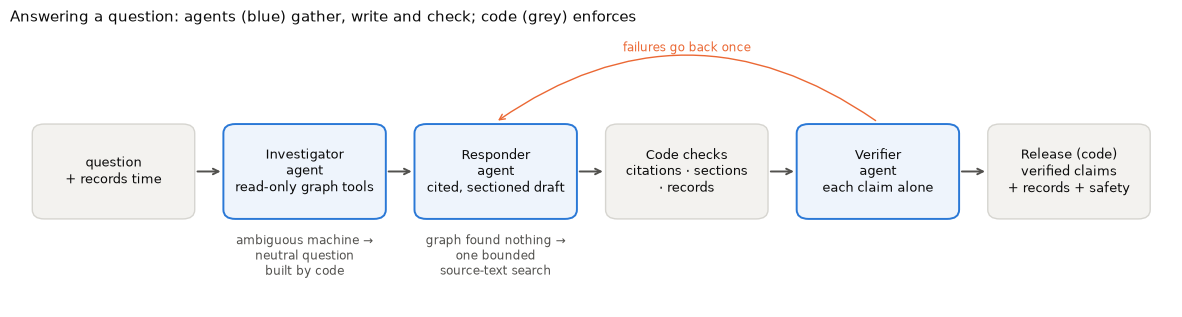

In [3]:
draw_answer_flow()

## 1. Records time and toolbox

The request sees only what was registered by 08:20. The investigator picks one typed,
read-only tool per turn; it never writes a query.

In [4]:
tools = GraphTools(bundle, DATASET, AS_OF, QUESTION)
print(f"Visible at 08:20: {len(tools.documents)} files, {len(tools.nodes)} of {len(bundle.nodes)} nodes")
tool_table(tools.definitions())

Visible at 08:20: 9 files, 47 of 66 nodes


,tool,arguments,what it does
0,find_equipment,query,Find equipment by ID/name/alias
1,walk_graph,"start_id, relations, direction, hops",Follow selected graph links up to three hops from a previously returned node
2,query_events,"equipment_id, event_code, since",Retrieve dated events on a resolved machine and its components
3,search_passages,"query, equipment_id, limit",Search eligible passages using words plus optional embedding similarity
4,search_documents,"query, limit","Fallback: search the source text of every file available at the question time, for what the other tools …"
5,query_history,equipment_id,Read up to ten dated maintenance cases for resolved equipment and its components
6,approved_parts,equipment_id,Find explicitly approved parts through equipment -> configuration <- part links
7,query_stock,equipment_id,Get reviewed stock counts for this machine's explicitly approved parts
8,troubleshooting_context,equipment_id,"For a stoppage or alarm on one resolved machine, gather its context in one graph traversal: installed …"
9,finish_retrieval,"outcome, question","Finish when the evidence covers the question, when the technician must clarify (ask one neutral …"


## 2. One graph call gathers the incident

`find_equipment("outfeed belt")` resolves CV-01 by its alias; `troubleshooting_context` then
collects everything relevant in one traversal:

In [5]:
tools.execute("find_equipment", {"query": "outfeed belt"})
ctx = tools.execute("troubleshooting_context", {"equipment_id": "CV-01"})
context_table(ctx, tools.cards)

,context,found,from files
0,machine,"CV-01, aliases ['outfeed belt', 'packing outfeed']",equipment_notes.txt
1,applicable manual,CT200-B rev 3 (via configuration B),"CT-200_configuration_B_rev3.pdf, equipment_notes.txt"
2,manual sections,"1. Applicability, 2. Motor overload, 3. Inspection boundary, 4. Replacement reference, 5. Other stops",CT-200_configuration_B_rev3.pdf
3,recorded events,"MOTOR_OVERLOAD × 2, RUNNING × 1",morning_export.log
4,alarm definitions,MOTOR_OVERLOAD: The simulated drive label MOTOR_OVERLOAD means motor …,CT-200_configuration_B_rev3.pdf
5,shift observations,"5 notes, of which 1 unverified suspicion",shift_handover.txt
6,past cases,"J-108 (setup then: unknown), J-071 (setup then: different recorded configuration)",maintenance_history.txt
7,procedures,SITE-M01 (full text in folder: False),"CT-200_configuration_B_rev3.pdf, site_maintenance_boundaries.txt"


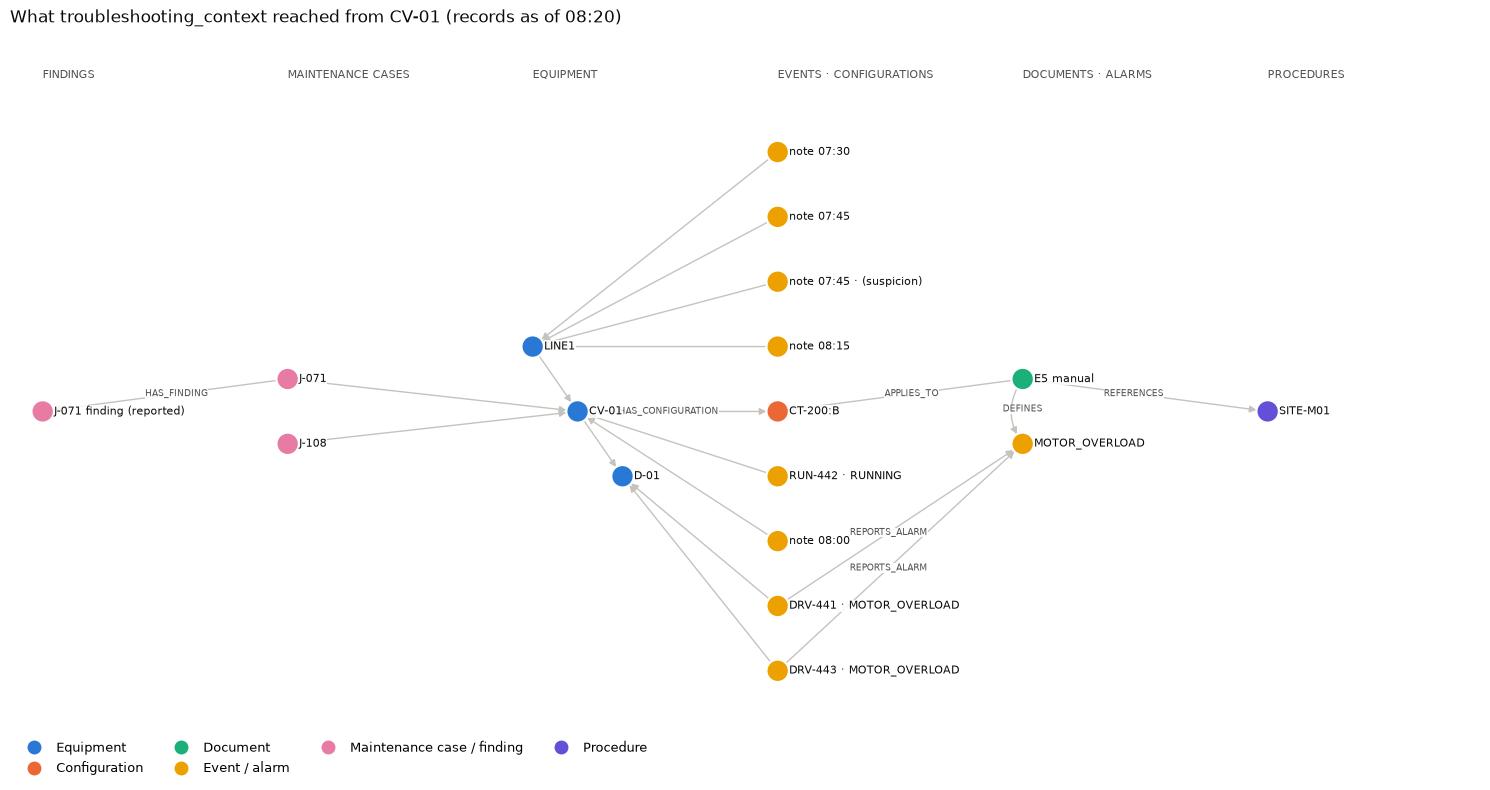

In [6]:
G = to_networkx(bundle)
draw_graph(G.subgraph(touched_nodes(tools)).copy(),
           "What troubleshooting_context reached from CV-01 (records as of 08:20)",
           edge_labels={"HAS_CONFIGURATION", "APPLIES_TO", "REPORTS_ALARM", "DEFINES", "REFERENCES", "HAS_FINDING"},
           size=(15, 8))

The manual comes through the configuration path (E5, not the archived E6), the duplicate export
counts once, and the operator's guess stays a guess.

## 3. Investigator, responder, checks

In [7]:
result, run_tools = ask(QUESTION)
investigation_table(result)

,step,tool,arguments,returned
0,1,find_equipment,"{""query"": ""outfeed belt""}",resolved CV-01
1,2,troubleshooting_context,"{""equipment_id"": ""CV-01""}","1 manual, 5 sections, 3 events, 5 shift notes, 2 past cases, 1 procedure"
2,3,search_passages,"{""query"": ""motor overload causes check outfeed belt"", …",6 passages
3,4,search_passages,"{""query"": ""motor overload causes outfeed belt inspection"", …",6 passages
4,5,query_history,"{""equipment_id"": ""CV-01""}",2 cases
5,6,finish_retrieval,"{""outcome"": ""answer"", ""question"": """"}",


In [8]:
first = ResponseDraft.model_validate(next(s for s in result.trace if s.get("stage") == "verify")["draft"])
draft_table(first, run_tools.cards)

,section,claim,cites
0,findings,The 'MOTOR_OVERLOAD' alarm on the outfeed belt drive means motor protection detected excessive loading ove...,"CT-200_configuration_B_rev3.pdf:11,12,13,14,15 + CT-200_configuration_B_rev3.pdf:12,13"
1,findings,Recent shift notes report scraping near the outfeed and the belt stopped twice with motor overload after c...,"shift_handover.txt:2,4 + shift_handover.txt:2,5 + shift_handover.txt:2,7 + shift_handover.txt:2,8 + shift_..."
2,findings,Historical maintenance found loose packing material obstructing the conveyor causing motor overload previo...,"maintenance_history.txt:3,4,5,6,7,8 + maintenance_history.txt:3,5 + maintenance_history.txt:16,17,18,19"
3,findings,"The equipment is confirmed as model CT-200, configuration B, which uses a motor, gearbox, drive, belt, sup...","equipment_notes.txt:4,5 + equipment_notes.txt:4,5; CT-200_configuration_B_rev3.pdf:4,5; approved_parts.txt..."
4,possible_causes,Mechanical resistance or obstruction such as binding rollers or loose packing material causing excessive m...,"CT-200_configuration_B_rev3.pdf:11,12,13,14,15 + CT-200_configuration_B_rev3.pdf:16,17,18,19,20,21 + maint..."
5,possible_causes,Motor-related problems or incorrect motor configuration could also cause motor overload.,"CT-200_configuration_B_rev3.pdf:11,12,13,14,15"
6,next_steps,"Perform physical inspection following the site-approved maintenance procedure SITE-M01, including checking...","CT-200_configuration_B_rev3.pdf:16,17,18,19,20,21 + site_maintenance_boundaries.txt:1,2,4,5,6,7 + site_mai..."
7,next_steps,Consult the maintenance lead if the detailed procedure is unavailable or if additional guidance is needed.,"CT-200_configuration_B_rev3.pdf:16,17,18,19,20,21"
8,record (code),events:0580c9ea292b59e8,
9,record (code),history:case:J-108,


In [9]:
checks_table(result)

,attempt,claims,issues found,details
0,1,8,0,all supported


Citations can only be card IDs this run returned. Code then checks section rules (a cause must
cite a manual; a next step must cite guidance; counts and stock are never restated), and the
verifier checks each claim alone.

## 4. What the verifier rejects

Same sources, cautious versus overstated claims:

In [10]:
card = {c.title: k for k, c in run_tools.cards.items()}
suspicion = next(k for k, c in run_tools.cards.items() if "UNVERIFIED_SUSPICION" in c.text)
causes = card["2. Motor overload"]
def verify(text, citations):
    return agent.structured(CLAIM_INSTRUCTIONS, {
        "question": QUESTION, "claim_id": "demo", "claim": text,
        "cited_cards": [run_tools.cards[k].model_dump() for k in citations]}, ClaimReview, reviewing=True)

examples = [
    ("An operator guessed the motor may be getting tired; no inspection was done.", [suspicion]),
    ("The motor is worn out and must be replaced.", [suspicion]),
    ("The manual lists mechanical resistance, such as binding rollers, as a possible cause of motor overload.", [causes]),
    ("Binding rollers caused today's overload stops.", [causes]),
]
rows = []
for text, cites in examples:
    review = verify(text, cites)
    rows.append({"claim": text, "cites": card_sources(run_tools.cards[cites[0]]),
                 "verdict": "✅ supported" if review.supported else "❌ rejected", "reason": review.reason})
pd.DataFrame(rows)

,claim,cites,verdict,reason
0,An operator guessed the motor may be getting tired; no inspection was done.,"shift_handover.txt:2,5,6",✅ supported,The cited card explicitly states the operator's suspicion that the motor may be getting tired with no insp...
1,The motor is worn out and must be replaced.,"shift_handover.txt:2,5,6",❌ rejected,The cited note only contains an unverified suspicion about the motor being tired without any inspection or...
2,"The manual lists mechanical resistance, such as binding rollers, as a possible cause of motor overload.","CT-200_configuration_B_rev3.pdf:11,12,13,14,15",✅ supported,The cited manual excerpt explicitly lists mechanical resistance or obstruction as possible causes of motor...
3,Binding rollers caused today's overload stops.,"CT-200_configuration_B_rev3.pdf:11,12,13,14,15",❌ rejected,The cited card states motor overload can be caused by mechanical resistance or obstruction among other iss...


## 5. The released answer

In [11]:
show_answer(result)

**Status:** `answered`

**What the records show**
- The 'MOTOR_OVERLOAD' alarm on the outfeed belt drive means motor protection detected excessive loading over time; it does not specify a unique failed component.
- Recent shift notes report scraping near the outfeed and the belt stopped twice with motor overload after carton size change and guide adjustments.
- Historical maintenance found loose packing material obstructing the conveyor causing motor overload previously and the material was removed.
- The equipment is confirmed as model CT-200, configuration B, which uses a motor, gearbox, drive, belt, support rollers, and package sensors.

**Possible causes to check**
- Mechanical resistance or obstruction such as binding rollers or loose packing material causing excessive motor load.
- Motor-related problems or incorrect motor configuration could also cause motor overload.

**Next steps**
- Perform physical inspection following the site-approved maintenance procedure SITE-M01, including checking for mechanical obstructions or resistance such as binding rollers.
- Consult the maintenance lead if the detailed procedure is unavailable or if additional guidance is needed.

**Records, rendered by code** (never rewritten by a model)
- *event count:* CV-01: 3 matching recorded events (all codes), from the available history through 2026-10-14T08:20:00+08:00. Duplicate exports count once. This is not live status.
- *maintenance record:* J-108 · 2026-10-08 · CV-01 · Reported problem: exit package detector unreliable. · Finding — not recorded · Recorded work: sensor PE-02 cleaned and alignment checked under site procedure. · Recorded outcome: package detection restored in the recorded test; no overload reported. · Setup recorded then: unknown. Current equipment setup: B.
- *maintenance record:* J-071 · 2026-08-18 · CV-01 · Reported problem: motor overload, outfeed stopped. · Finding — reported in the source: loose packing material obstructing conveyor. · Recorded work: material removed under site maintenance procedure. · Recorded outcome: trial run completed without another overload during that trial. · Setup recorded then: A. Current equipment setup: B. These recorded setups differ.
- *safety boundary:* Physical checks follow the site procedure (SITE-M01) and are for authorised staff. The full procedure is not in these records: ask the maintenance lead for it.

In [12]:
display(sources_table(result))
text, refs = claim_lines(result, "possible_causes", 0)
print("Exact lines behind:", repr(text))
evidence_frame(refs)

,section,statement,sources
0,findings,The 'MOTOR_OVERLOAD' alarm on the outfeed belt drive means motor protection …,"CT-200_configuration_B_rev3.pdf l.11,12,13,14,15"
1,findings,Recent shift notes report scraping near the outfeed and the belt stopped twice …,"shift_handover.txt l.1,2,4,5,6,7,8"
2,findings,Historical maintenance found loose packing material obstructing the conveyor …,"maintenance_history.txt l.3,4,5,6,7,8,16,17,18,19"
3,findings,"The equipment is confirmed as model CT-200, configuration B, which uses a …","equipment_notes.txt l.1,2,4,5,6,7,8; CT-200_configuration_B_rev3.pdf l.4,5,7,8,9,10; approved_parts.txt l...."
4,possible_causes,Mechanical resistance or obstruction such as binding rollers or loose packing …,"CT-200_configuration_B_rev3.pdf l.11,12,13,14,15,16,17,18,19,20,21; maintenance_history.txt l.3,5"
5,possible_causes,Motor-related problems or incorrect motor configuration could also cause motor …,"CT-200_configuration_B_rev3.pdf l.11,12,13,14,15"
6,next_steps,Perform physical inspection following the site-approved maintenance procedure …,"CT-200_configuration_B_rev3.pdf l.16,17,18,19,20,21; site_maintenance_boundaries.txt l.1,2,4,5,6,7,9,10,11..."
7,next_steps,Consult the maintenance lead if the detailed procedure is unavailable or if …,"CT-200_configuration_B_rev3.pdf l.16,17,18,19,20,21"


Exact lines behind: 'Mechanical resistance or obstruction such as binding rollers or loose packing material causing excessive motor load.'


,source,file,line,page,exact text in the file
0,E5,CT-200_configuration_B_rev3.pdf,11,1,2. Motor overload
1,E5,CT-200_configuration_B_rev3.pdf,12,1,The simulated drive label MOTOR_OVERLOAD means motor protection detected excessive loading
2,E5,CT-200_configuration_B_rev3.pdf,13,1,over time. The label does not identify a unique failed component. Possible explanations include
3,E5,CT-200_configuration_B_rev3.pdf,14,1,"mechanical resistance or obstruction, motor-related problems, or incorrect motor configuration. A"
4,E5,CT-200_configuration_B_rev3.pdf,15,1,"recent product change is context, not proof of cause."
5,E5,CT-200_configuration_B_rev3.pdf,16,1,3. Inspection boundary
6,E5,CT-200_configuration_B_rev3.pdf,17,1,Use the site-approved maintenance procedure referenced as SITE-M01. Physical checks require
7,E5,CT-200_configuration_B_rev3.pdf,18,1,"authorised staff and the site's isolation and verification process. Review existing observations,"
8,E5,CT-200_configuration_B_rev3.pdf,19,1,including where noise was heard. Binding rollers are one possible source of resistance. If the
9,E5,CT-200_configuration_B_rev3.pdf,20,1,"required detailed procedure is unavailable, consult the maintenance lead. This summary does not"


Records (count, past jobs, safety boundary) are rendered by code from the graph, so a model
never rewrites a quantity or a finding's certainty.

## 6. Follow-up and an unclear machine

In [13]:
FOLLOW_UP = ("After isolation and inspection under our procedure we found a roller underneath the belt "
             "that barely turns. Cartons and side guides were clear. Which part do we need, and is one in stock?")
follow, follow_tools = ask(conversation_context([{"message": QUESTION}], FOLLOW_UP))
show_answer(follow)

**Status:** `answered`

**What the records show**
- The outfeed belt CV-01 stopped twice with motor overload errors after carton size changeover, and inspection found a roller underneath the belt that barely turns. Cartons and side guides were clear, so obstruction was not causing the problem.

**Possible causes to check**
- Motor overload can be caused by mechanical resistance such as a binding roller, motor issues, or incorrect motor setup. A roller that barely turns can cause mechanical resistance leading to overload.

**Next steps**
- Replace the underside return roller assembly with the approved part RA-200B, which includes the roller and bearings, specific to CT-200 configuration B. Confirm stock availability with stores.

**Records, rendered by code** (never rewritten by a model)
- *event count:* CV-01: 3 matching recorded events (all codes), from the available history through 2026-10-14T08:20:00+08:00. Duplicate exports count once. This is not live status.
- *maintenance record:* J-108 · 2026-10-08 · CV-01 · Reported problem: exit package detector unreliable. · Finding — not recorded · Recorded work: sensor PE-02 cleaned and alignment checked under site procedure. · Recorded outcome: package detection restored in the recorded test; no overload reported. · Setup recorded then: unknown. Current equipment setup: B.
- *maintenance record:* J-071 · 2026-08-18 · CV-01 · Reported problem: motor overload, outfeed stopped. · Finding — reported in the source: loose packing material obstructing conveyor. · Recorded work: material removed under site maintenance procedure. · Recorded outcome: trial run completed without another overload during that trial. · Setup recorded then: A. Current equipment setup: B. These recorded setups differ.
- *stock record:* RA-200B · approved part for CV-01 · Location: B-12 · Counted at: 13 Oct 2026, 16:00 (+0800) · Recorded quantity: 1 · Reservations: not recorded; do not assume zero. · Free stock is not calculated. Confirm availability with stores.
- *safety boundary:* Physical checks follow the site procedure (SITE-M01) and are for authorised staff. The full procedure is not in these records: ask the maintenance lead for it.

In [14]:
unclear, _ = ask("The outfeed stopped. What should I check?")
show_answer(unclear)

**Status:** `clarification`

**Question for you:** Which machine do you mean: CV-01 (outfeed belt) or CV-02 (case packer outfeed)?

- The follow-up names the approved part (RA-200B for configuration B) and the dated stock count.
- "Outfeed" alone is ambiguous: tools refuse to act on an unresolved machine, and code asks a
  neutral question.

## Summary

| Step | Guards against |
|---|---|
| Records time | information the technician did not have yet |
| Typed read-only tools; machines must resolve | invented queries; guessed machines |
| Citations limited to returned IDs | invented sources |
| Code rules + per-claim verifier | guesses or possibilities stated as facts |
| Records and safety boundary by code | rewritten quantities; missing safety note |

Next: [03_evaluation.ipynb](03_evaluation.ipynb).